In [101]:
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
import sklearn

print("Everything works!")

Everything works!


In [102]:
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split

# Task 1 Data Preparation and Normalization

## Prepare independent setup configurations

In [103]:
# Read data
df_raw = pd.read_csv("ims_setup_project02.csv")

print("First five rows:")
display(df_raw.head())

print("Shape:", df_raw.shape)

print("\nColumn names:")
display(df_raw.columns)

print("\nMissing values:")
display(df_raw.isna().sum())

First five rows:


,lap,rear_wing_angle_deg,rear_ride_height_mm,sector_3_time_s,top_speed_kph
0,1,5,35,33.0949,286.761
1,2,5,35,32.9325,287.079
2,3,5,35,33.0858,287.261
3,4,5,35,33.0472,287.059
4,5,5,35,33.0534,287.463


Shape: (135, 5)

Column names:


Index(['lap', 'rear_wing_angle_deg', 'rear_ride_height_mm', 'sector_3_time_s',
       'top_speed_kph'],
      dtype='str')


Missing values:


lap                    0
rear_wing_angle_deg    0
rear_ride_height_mm    0
sector_3_time_s        0
top_speed_kph          0
dtype: int64

In [104]:
import numpy as np
import pandas as pd
from IPython.display import display

# Read CSV
df_raw = pd.read_csv("ims_setup_project02.csv")

# Keep required columns
df = df_raw[
    [
        "lap",
        "rear_wing_angle_deg",
        "rear_ride_height_mm",
        "sector_3_time_s"
    ]
].copy()

# Convert to numeric
df = df.apply(pd.to_numeric, errors="coerce")

# Remove exact duplicates
df = df.drop_duplicates()

# Remove missing values
df = df.dropna()

print("Cleaned DataFrame:")
display(df.head())

print("Shape:", df.shape)

Cleaned DataFrame:


,lap,rear_wing_angle_deg,rear_ride_height_mm,sector_3_time_s
0,1,5,35,33.0949
1,2,5,35,32.9325
2,3,5,35,33.0858
3,4,5,35,33.0472
4,5,5,35,33.0534


Shape: (135, 4)


In [105]:
df_grouped = (
    df.groupby(
        ["rear_wing_angle_deg", "rear_ride_height_mm"]
    )
    .agg(
        mean_sector_3_time_s=("sector_3_time_s", "mean"),
        std_sector_3_time_s=("sector_3_time_s", "std"),
        valid_laps=("sector_3_time_s", "count")
    )
    .reset_index()
)

print("Grouped DataFrame:")
display(df_grouped)

print("Number of setup configurations:", len(df_grouped))

Grouped DataFrame:


,rear_wing_angle_deg,rear_ride_height_mm,mean_sector_3_time_s,std_sector_3_time_s,valid_laps
0,5,35,33.04276,0.064925,5
1,5,40,32.85104,0.104126,5
2,5,45,32.99286,0.022043,5
3,6,35,32.51308,0.053101,5
4,6,40,32.38096,0.050323,5
5,6,45,32.44690,0.077138,5
6,7,35,32.03248,0.035651,5
7,7,40,31.86244,0.059775,5
8,7,45,32.01484,0.053106,5
9,8,35,31.68490,0.054910,5


Number of setup configurations: 27


In [106]:
df_grouped.to_csv(
    "cvanvoor_pr03_grouped.csv",
    index=False
)

print("cvanvoor_pr03_grouped.csv saved successfully.")

cvanvoor_pr03_grouped.csv saved successfully.


In [107]:
len(df_grouped)

27

In [108]:
# Step 2

# Sort grouped data
df_grouped = (
    df_grouped
    .sort_values(
        ["rear_wing_angle_deg", "rear_ride_height_mm"]
    )
    .reset_index(drop=True)
)

# Add unique setup ID
df_grouped["setup_id"] = np.arange(len(df_grouped))

# Train/test split
df_train, df_test = train_test_split(
    df_grouped,
    test_size=0.25,
    random_state=42
)

print("Training configurations:", len(df_train))
print("Test configurations:", len(df_test))

print("\nTraining shape:", df_train.shape)
print("Test shape:", df_test.shape)

display(df_train.head())
display(df_test.head())

Training configurations: 20
Test configurations: 7

Training shape: (20, 6)
Test shape: (7, 6)


,rear_wing_angle_deg,rear_ride_height_mm,mean_sector_3_time_s,std_sector_3_time_s,valid_laps,setup_id
17,10,45,31.44488,0.032345,5,17
12,9,35,31.44076,0.077286,5,12
24,13,35,31.59024,0.068500,5,24
1,5,40,32.85104,0.104126,5,1
4,6,40,32.38096,0.050323,5,4


,rear_wing_angle_deg,rear_ride_height_mm,mean_sector_3_time_s,std_sector_3_time_s,valid_laps,setup_id
8,7,45,32.01484,0.053106,5,8
13,9,40,31.34738,0.065261,5,13
9,8,35,31.68490,0.054910,5,9
21,12,35,31.41880,0.050465,5,21
0,5,35,33.04276,0.064925,5,0


### Why repeated laps must remain together by setup:
The train/test split is performed after grouping the repeated laps into setup configurations because the goal is to predict the performance of unseen setups, not individual laps. Multiple laps from the same setup are not independent observations because they share the same rear-wing angle and rear ride height.

If laps from a single setup were split between the training and test sets, the model would effectively be evaluated on data that are very similar to data it already saw during training. This would lead to information leakage and overly optimistic estimates of prediction accuracy.

By grouping first and then splitting by setup configuration, each setup appears entirely in the training set or entirely in the test set, providing a more realistic estimate of model performance on unseen designs.

# Normalize the two physical inputs

In [109]:
# Step 3

# Inputs (keep 2-D)
X_train = df_train[
    ["rear_wing_angle_deg", "rear_ride_height_mm"]
].to_numpy()

X_test = df_test[
    ["rear_wing_angle_deg", "rear_ride_height_mm"]
].to_numpy()

# Response (keep 1-D)
y_train = df_train["mean_sector_3_time_s"].to_numpy()

y_test = df_test["mean_sector_3_time_s"].to_numpy()

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (20, 2)
X_test shape: (7, 2)
y_train shape: (20,)
y_test shape: (7,)


In [110]:
# Step 4: Verify Bounds

print("Wing angle range in dataset:")
print(
    df_grouped["rear_wing_angle_deg"].min(),
    "to",
    df_grouped["rear_wing_angle_deg"].max()
)

print("\nRide height range in dataset:")
print(
    df_grouped["rear_ride_height_mm"].min(),
    "to",
    df_grouped["rear_ride_height_mm"].max()
)

Wing angle range in dataset:
5 to 13

Ride height range in dataset:
35 to 45


In [111]:
# Step 4: Define Fixed Bounds

# Fixed normalization bounds
wing_min = 5.0
wing_max = 13.0

ride_min = 35.0
ride_max = 45.0

print("Wing angle bounds:", wing_min, "to", wing_max)
print("Ride height bounds:", ride_min, "to", ride_max)

Wing angle bounds: 5.0 to 13.0
Ride height bounds: 35.0 to 45.0


In [112]:
# Step 4: Normalize Inputs

# Create normalized copies
X_train_n = X_train.copy().astype(float)
X_test_n = X_test.copy().astype(float)

# Wing angle normalization
X_train_n[:, 0] = (
    (X_train[:, 0] - wing_min)
    / (wing_max - wing_min)
)

X_test_n[:, 0] = (
    (X_test[:, 0] - wing_min)
    / (wing_max - wing_min)
)

# Ride height normalization
X_train_n[:, 1] = (
    (X_train[:, 1] - ride_min)
    / (ride_max - ride_min)
)

X_test_n[:, 1] = (
    (X_test[:, 1] - ride_min)
    / (ride_max - ride_min)
)

print("Normalized training inputs:")
display(pd.DataFrame(
    X_train_n,
    columns=["z1", "z2"]
).head())

print("Normalized test inputs:")
display(pd.DataFrame(
    X_test_n,
    columns=["z1", "z2"]
).head())

Normalized training inputs:


,z1,z2
0,0.625,1.0
1,0.500,0.0
2,1.000,0.0
3,0.000,0.5
4,0.125,0.5


Normalized test inputs:


,z1,z2
0,0.250,1.0
1,0.500,0.5
2,0.375,0.0
3,0.875,0.0
4,0.000,0.0


### Input Normalization

The physical design variables were normalized using the fixed domain bounds specified in the project instructions.

* Rear-wing angle: 5 to 13 deg
* Rear ride height: 35 to 45 mm

The normalization was performed using

$$
z_j=\frac{x_j-l_j}{u_j-l_j}
$$

where $l_j$ and $u_j$ are the lower and upper bounds for each design variable. These bounds will remain fixed for all LOOCV folds, model fitting, validation, and plotting tasks. The response variable (mean Sector 3 time) was not normalized.

# Task 2: Gaussian RBF Model

### Implement and check the model

In [113]:
# Step 5

def rbf_matrix(A, B, sigma):
    """
    Compute Gaussian RBF kernel matrix between
    every row of A and every row of B.
    """

    # Pairwise squared Euclidean distance
    sq_dist = np.sum(
        (A[:, None, :] - B[None, :, :])**2,
        axis=2
    )

    # Gaussian kernel
    Phi = np.exp(
        -sq_dist / (2 * sigma**2)
    )

    return Phi


In [114]:
sigma_test = 0.20

Phi_train = rbf_matrix(
    X_train_n,
    X_train_n,
    sigma_test
)

print("Training Gram matrix shape:")
print(Phi_train.shape)

print("\nFirst five diagonal entries:")
print(np.diag(Phi_train)[:5])

Training Gram matrix shape:
(20, 20)

First five diagonal entries:
[1. 1. 1. 1. 1.]


## Step 5 Markdown Cell

### Gaussian RBF Gram Matrix Verification

The Gaussian RBF kernel was implemented using squared Euclidean distance in the normalized two-input space.

$$
\phi(\mathbf z,\mathbf c;\sigma)
=
\exp\left(
-\frac{\|\mathbf z-\mathbf c\|^2}{2\sigma^2}
\right)
$$

Using the normalized training inputs, the resulting Gram matrix had shape (20, 20), matching the number of training configurations. The diagonal entries were verified to equal 1 because the distance between each point and itself is zero.

In [115]:
# Step 6

def fit_rbf(X, y, sigma, lam):
    """
    Fit Gaussian RBF model.

    Parameters
    ----------
    X : training inputs
    y : training responses
    sigma : RBF width
    lam : regularization parameter

    Returns
    -------
    b : fitted RBF weights
    """

    # Training Gram matrix
    Phi = rbf_matrix(X, X, sigma)

    n = Phi.shape[0]

    # Solve (Phi + lam*I)b = y
    b = np.linalg.solve(
        Phi + lam * np.eye(n),
        y
    )

    return b


def predict_rbf(X_new, centers, b, sigma):
    """
    Predict responses at new locations.
    """

    Phi_new = rbf_matrix(
        X_new,
        centers,
        sigma
    )

    y_hat = Phi_new @ b

    return y_hat

In [116]:
sigma_test = 0.20
lam_test = 0.01

# Fit model
b_test = fit_rbf(
    X_train_n,
    y_train,
    sigma_test,
    lam_test
)

# Predict training points
y_hat_train = predict_rbf(
    X_train_n,
    X_train_n,
    b_test,
    sigma_test
)

print("Weight vector shape:", b_test.shape)

print("Prediction shape:", y_hat_train.shape)

print("\nFirst five predictions:")
print(y_hat_train[:5])

Weight vector shape: (20,)
Prediction shape: (20,)

First five predictions:
[31.60538492 31.24585212 31.33051798 32.47028796 32.61044921]


## Step 6 Markdown Cell

### Gaussian RBF Model Functions

The Gaussian RBF weights were obtained by solving

$$
(\Phi+\lambda I)\mathbf b=\mathbf y
$$ 

using np.linalg.solve. The training configurations were used as the RBF centers. Predictions at new locations were computed using the same Gaussian kernel and the fitted weight vector. Matrix inversion was not performed explicitly.

In [117]:
# Step 7: Build Both Models

from scipy.interpolate import RBFInterpolator

sigma = 0.20
lam = 0.01

# Our implementation
b_rbf = fit_rbf(
    X_train_n,
    y_train,
    sigma,
    lam
)

# SciPy implementation
rbf_scipy = RBFInterpolator(
    X_train_n,
    y_train,
    kernel="gaussian",
    epsilon=1 / (np.sqrt(2) * sigma),
    smoothing=lam,
    degree=-1
)

In [118]:
# Step 7: Compare at Training Inputs

# Predictions from the model
y_hat_ours = predict_rbf(
    X_train_n,
    X_train_n,
    b_rbf,
    sigma
)

# Predictions from SciPy
y_hat_scipy = rbf_scipy(X_train_n)

# Maximum absolute difference
max_diff_train = np.max(
    np.abs(y_hat_ours - y_hat_scipy)
)

print("Maximum training-point difference:")
print(max_diff_train)

Maximum training-point difference:
2.1316282072803006e-14


In [119]:
# Step 7: Five Additional Points

X_check = np.array([
    [0.10, 0.10],
    [0.25, 0.70],
    [0.50, 0.50],
    [0.75, 0.20],
    [0.90, 0.90]
])

# Predictions
y_check_ours = predict_rbf(
    X_check,
    X_train_n,
    b_rbf,
    sigma
)

# SciPy predictions
y_check_scipy = rbf_scipy(X_check)

# Differences
diff_check = np.abs(
    y_check_ours - y_check_scipy
)

print("Prediction comparison at additional points:")
comparison = pd.DataFrame({
    "our_prediction": y_check_ours,
    "scipy_prediction": y_check_scipy,
    "abs_difference": diff_check
})

display(comparison)

max_diff_extra = np.max(diff_check)

print("\nMaximum additional-point difference:")
print(max_diff_extra)

Prediction comparison at additional points:


,our_prediction,scipy_prediction,abs_difference
0,30.717101,30.717101,7.105427e-15
1,26.756299,26.756299,7.105427e-15
2,30.900439,30.900439,7.105427e-15
3,27.390094,27.390094,1.065814e-14
4,31.069764,31.069764,2.131628e-14



Maximum additional-point difference:
2.1316282072803006e-14


## Step 7 Markdown Cell

### Verification Against SciPy RBFInterpolator

The custom Gaussian RBF implementation was compared against
`scipy.interpolate.RBFInterpolator` using identical training data,
σ = 0.20 and λ = 0.01.

The maximum absolute prediction difference at the training configurations was
2.13 × 10⁻¹⁴ s. The maximum absolute prediction difference at five additional
points within the normalized domain was also 2.13 × 10⁻¹⁴ s.

Both differences were many orders of magnitude smaller than the specified
tolerance of 1 × 10⁻⁶ s, indicating that the custom implementation is
numerically equivalent to the SciPy reference implementation for this problem.

## Establish the default RBF model

In [120]:
# Step 8

sigma_default = 0.20
lam_default = 0.01

# Fit default RBF model
b_default = fit_rbf(
    X_train_n,
    y_train,
    sigma_default,
    lam_default
)

# Predict training configurations
y_train_pred = predict_rbf(
    X_train_n,
    X_train_n,
    b_default,
    sigma_default
)

# Training RMSE
train_rmse = np.sqrt(
    np.mean(
        (y_train - y_train_pred) ** 2
    )
)

print("Default sigma:", sigma_default)
print("Default lambda:", lam_default)
print("Training RMSE (s):", train_rmse)

Default sigma: 0.2
Default lambda: 0.01
Training RMSE (s): 0.2533624196554888


## Step 8 Markdown Cell

### Default Gaussian RBF Model

The default Gaussian RBF model was fit using

$$
\sigma = 0.20
$$

and

$$
\lambda = 0.01
$$

The resulting training RMSE was 0.2533624196554888 seconds.

The fitted parameters of the model are the elements of the weight vector

$$
\mathbf b
$$

which are obtained by solving

$$
(\Phi + \lambda I)\mathbf b = \mathbf y.
$$

These weights are determined from the training data.

The hyperparameters are

$$
\sigma
$$

and

$$
\lambda.
$$

The parameter

$$
\sigma
$$

controls the width of the Gaussian basis functions, while

$$
\lambda
$$

controls the amount of regularization applied during fitting. Unlike the fitted weights, the hyperparameters are selected by the analyst and are not directly estimated from the response values.

All remaining tasks in Parts II–V use the custom RBF functions developed in this project. SciPy was used only for the numerical equivalence check in Step 7.

# Task 3: LOOCV and Hyperparameter Optimization

### Implement leave one out cross validation

In [121]:
# Step 9

def loocv_rbf(X, y, sigma, lam):
    """
    Leave-One-Out Cross Validation for Gaussian RBF.

    Returns
    -------
    y_pred : LOOCV prediction for every omitted point
    """

    n = len(y)

    y_pred = np.zeros(n)

    for i in range(n):

        # Remove observation i
        X_fit = np.delete(X, i, axis=0)
        y_fit = np.delete(y, i)

        # Point being predicted
        X_left_out = X[i].reshape(1, -1)

        # Refit model
        b = fit_rbf(
            X_fit,
            y_fit,
            sigma,
            lam
        )

        # Predict omitted point
        y_pred[i] = predict_rbf(
            X_left_out,
            X_fit,
            b,
            sigma
        )[0]

    return y_pred

In [122]:
# Step 9: Verification

y_loocv_default = loocv_rbf(
    X_train_n,
    y_train,
    sigma_default,
    lam_default
)

print("LOOCV prediction shape:")
print(y_loocv_default.shape)

print("\nFirst five LOOCV predictions:")
print(y_loocv_default[:5])

LOOCV prediction shape:
(20,)

First five LOOCV predictions:
[32.17281635 29.49617915 15.37656384 26.18485562 33.57258031]


## Step 9 Markdown Cell

### Leave-One-Out Cross Validation Function

The LOOCV procedure removes one training setup at a time, refits the RBF model using the remaining configurations, and predicts the omitted response. The omitted setup is removed from both the fitting observations and the RBF centers. The model weights are recalculated in each fold and are not reused from the full-data fit.

In [123]:
# Step 10

# LOOCV residuals
residuals_default = y_train - y_loocv_default

# PRESS
PRESS_default = np.sum(
    residuals_default**2
)

# RMSE_CV
RMSE_CV_default = np.sqrt(
    PRESS_default / len(y_train)
)

print("Training RMSE (s):", train_rmse)
print("PRESS:", PRESS_default)
print("RMSE_CV (s):", RMSE_CV_default)

Training RMSE (s): 0.2533624196554888
PRESS: 606.205223730506
RMSE_CV (s): 5.505475564065769


## Step 10 Markdown Cell

### Default LOOCV Results

Leave-one-out cross validation was performed using the default hyperparameters

$$
\sigma = 0.20
$$

and

$$
\lambda = 0.01.
$$

The resulting PRESS value was **606.2052** and the resulting cross-validation RMSE was **5.5055 s**.

For comparison, the default model training RMSE was **0.2534 s**.

The cross-validation RMSE is much larger than the training RMSE because each prediction is made for a setup that was omitted from the corresponding fold fit. This demonstrates that a small training error alone does not guarantee good predictive performance. PRESS and RMSE_CV provide a more realistic estimate of how well the model predicts unseen setup configurations.

## Search jointly over sigma and lambda

In [124]:
# Step 11

# Hyperparameter grids
sigma_values = np.logspace(-1.3, 0, 15)
lam_values = np.logspace(-8, 0, 9)

print("Number of sigma values:", len(sigma_values))
print("Number of lambda values:", len(lam_values))
print("Total combinations:", len(sigma_values) * len(lam_values))


Number of sigma values: 15
Number of lambda values: 9
Total combinations: 135


In [125]:
# Step 11: Main Hyperparameter Search Cell

search_results = []

for sigma in sigma_values:
    
    for lam in lam_values:
        
        try:
            
            # LOOCV predictions
            y_loocv = loocv_rbf(
                X_train_n,
                y_train,
                sigma,
                lam
            )
            
            # Residuals
            residuals = y_train - y_loocv
            
            # PRESS
            PRESS = np.sum(
                residuals**2
            )
            
            # RMSE_CV
            RMSE_CV = np.sqrt(
                PRESS / len(y_train)
            )
            
            search_results.append({
                "sigma": sigma,
                "lam": lam,
                "PRESS": PRESS,
                "RMSE_CV": RMSE_CV
            })
            
        except Exception:
            
            search_results.append({
                "sigma": sigma,
                "lam": lam,
                "PRESS": np.inf,
                "RMSE_CV": np.inf
            })

print("Completed", len(search_results), "hyperparameter evaluations.")


Completed 135 hyperparameter evaluations.


## Step 11 Markdown Cell

### Hyperparameter Search Grid

The RBF hyperparameters were evaluated over the specified logarithmically spaced grid:

$$
\sigma \in \text{logspace}(-1.3, 0, 15)
$$

$$
\lambda \in \text{logspace}(-8, 0, 9)
$$

This produced 135 hyperparameter combinations. For each pair, leave-one-out
cross validation was performed and RMSE_CV was calculated using the training
configurations only.


In [126]:
# Step 12

search_results = []

for sigma in sigma_values:

    for lam in lam_values:

        try:

            # LOOCV predictions
            y_loocv = loocv_rbf(
                X_train_n,
                y_train,
                sigma,
                lam
            )

            # Check for nonfinite values
            if not np.all(np.isfinite(y_loocv)):
                raise ValueError("Nonfinite predictions")

            residuals = y_train - y_loocv

            PRESS = np.sum(
                residuals**2
            )

            RMSE_CV = np.sqrt(
                PRESS / len(y_train)
            )

            if not np.isfinite(PRESS) or not np.isfinite(RMSE_CV):
                raise ValueError("Nonfinite objective")

            status = "success"

        except Exception:

            PRESS = np.inf
            RMSE_CV = np.inf
            status = "failed"

        search_results.append({
            "sigma": sigma,
            "lam": lam,
            "PRESS": PRESS,
            "RMSE_CV": RMSE_CV,
            "status": status
        })

# Create required DataFrame
df_cv_search = pd.DataFrame(search_results)

print("Number of rows:", len(df_cv_search))
display(df_cv_search.head())

Number of rows: 135


,sigma,lam,PRESS,RMSE_CV,status
0,0.050119,1.000000e-08,18035.742595,30.029771,success
1,0.050119,1.000000e-07,18035.742783,30.029771,success
2,0.050119,1.000000e-06,18035.744663,30.029772,success
3,0.050119,1.000000e-05,18035.763465,30.029788,success
4,0.050119,1.000000e-04,18035.951461,30.029945,success


In [127]:
# Step 12: Verify

print(df_cv_search["status"].value_counts())

status
success    135
Name: count, dtype: int64


## Step 12 Markdown Cell

### Hyperparameter Search Results

A total of 135 hyperparameter combinations were evaluated using leave-one-out
cross validation.

For each combination, PRESS and RMSE_CV were calculated from the LOOCV
predictions. A status flag was included for every run. If a solve failed or
produced nonfinite values, the corresponding PRESS and RMSE_CV values were set
to infinity and the status was recorded as "failed". Otherwise, the run was
recorded as "success".

In [128]:
# Step 13

# Successful runs only
df_success = df_cv_search[
    df_cv_search["status"] == "success"
].copy()

# Sort according to project rules
df_success = df_success.sort_values(
    by=["RMSE_CV", "lam", "sigma"],
    ascending=[True, False, True]
)

# Five best pairs
best_five = df_success.head(5)

print("Five best hyperparameter pairs:")
display(best_five)

# Selected pair
best_row = df_success.iloc[0]

sigma_star = best_row["sigma"]
lam_star = best_row["lam"]
RMSE_CV_star = best_row["RMSE_CV"]

print("Selected sigma:", sigma_star)
print("Selected lambda:", lam_star)
print("Best RMSE_CV:", RMSE_CV_star)

Five best hyperparameter pairs:


,sigma,lam,PRESS,RMSE_CV,status
108,0.652057,1.000000e-08,0.126111,0.079407,success
117,0.807501,1.000000e-08,0.150051,0.086617,success
109,0.652057,1.000000e-07,0.154902,0.088006,success
129,1.000000,1.000000e-05,0.162077,0.090021,success
99,0.526537,1.000000e-08,0.171398,0.092574,success


Selected sigma: 0.6520572293428615
Selected lambda: 1e-08
Best RMSE_CV: 0.07940735948368716


In [129]:
# Step 13: Calculate Percentage Reduction

percent_reduction = (
    (RMSE_CV_default - RMSE_CV_star)
    / RMSE_CV_default
) * 100

print("Percent reduction in RMSE_CV:")
print(percent_reduction)

Percent reduction in RMSE_CV:
98.55766575367296


## Step 13 Markdown Cell

### Selection of Optimal Hyperparameters

All 135 hyperparameter combinations were evaluated using leave-one-out cross validation.

The successful combinations were ranked by RMSE_CV. In the event of an exact tie,
the project tie-breaking rules were applied by selecting the larger λ value and,
if necessary, the smaller σ value.

The selected hyperparameters were

$$
\sigma^* = 0.652057
$$

and

$$
\lambda^* = 1.0 \times 10^{-8}.
$$

The corresponding cross-validation RMSE was **0.0794 s**.

Compared with the default model, the selected hyperparameters produced a
**98.56% reduction** in RMSE_CV.

A negative percentage reduction would indicate that the selected model performs
worse than the default model, even after the hyperparameter search. In this
case, the hyperparameter search substantially improved predictive performance
relative to the default model.

## Visualize the search and inspect the selected model

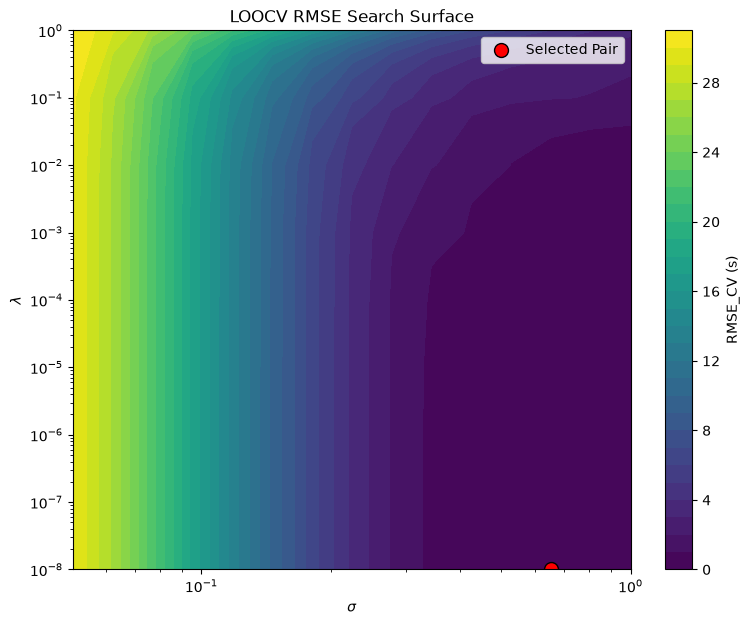

In [130]:
# Step 14: Create the RMSE_CV Contour Plot

import matplotlib.pyplot as plt

# Create pivot table
rmse_grid = df_cv_search.pivot(
    index="lam",
    columns="sigma",
    values="RMSE_CV"
)

# Convert to arrays for contour plot
Sigma, Lambda = np.meshgrid(
    rmse_grid.columns.values,
    rmse_grid.index.values
)

RMSE = rmse_grid.values

# Mask any failed combinations
RMSE_masked = np.ma.masked_invalid(RMSE)

# Create figure
plt.figure(figsize=(9, 7))

contour = plt.contourf(
    Sigma,
    Lambda,
    RMSE_masked,
    levels=30,
    cmap="viridis"
)

plt.colorbar(
    contour,
    label="RMSE_CV (s)"
)

# Mark selected hyperparameters
plt.scatter(
    sigma_star,
    lam_star,
    color="red",
    edgecolors="black",
    s=100,
    label="Selected Pair"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel(r"$\sigma$")
plt.ylabel(r"$\lambda$")
plt.title("LOOCV RMSE Search Surface")

plt.legend()
plt.show()

## Step 14 Markdown Cell

### Hyperparameter Search Surface

A filled contour plot was created showing RMSE_CV as a function of the RBF
hyperparameters σ and λ. Both axes were displayed on logarithmic scales and
the selected hyperparameter pair was marked on the plot.

The selected pair was

$$
\sigma^* = 0.652057
$$

and

$$
\lambda^* = 1.0 \times 10^{-8}.
$$

The selected λ value occurs at the lower boundary of the search range,
indicating that the best cross-validation performance was achieved with very
little regularization. Because the optimum is located on a search boundary,
the result does not prove that the true optimum lies within the tested search
range. A lower λ value could potentially produce an even lower RMSE_CV, but
that possibility was not explored in this search.

The low-error region appears relatively broad rather than concentrated at a
single sharp minimum. This suggests that model performance is not extremely
sensitive to small changes in the hyperparameters near the selected solution.
The contour plot also indicates that σ has a larger influence on RMSE_CV than
λ, as the error changes primarily when moving across σ values.

In [131]:
# Step 15 

# LOOCV predictions at optimal hyperparameters
y_loocv_opt = loocv_rbf(
    X_train_n,
    y_train,
    sigma_star,
    lam_star
)

# Build required results table
df_loocv = df_train[
    [
        "setup_id",
        "rear_wing_angle_deg",
        "rear_ride_height_mm"
    ]
].copy()

df_loocv["actual_time_s"] = y_train
df_loocv["predicted_time_s"] = y_loocv_opt

# Residual = actual - predicted
df_loocv["residual_s"] = (
    df_loocv["actual_time_s"]
    - df_loocv["predicted_time_s"]
)

display(df_loocv)

,setup_id,rear_wing_angle_deg,rear_ride_height_mm,actual_time_s,predicted_time_s,residual_s
17,17,10,45,31.44488,31.440167,0.004713
12,12,9,35,31.44076,31.452658,-0.011898
24,24,13,35,31.59024,31.366482,0.223758
1,1,5,40,32.85104,33.030382,-0.179342
4,4,6,40,32.38096,32.336081,0.044879
5,5,6,45,32.44690,32.410609,0.036291
2,2,5,45,32.99286,33.047647,-0.054787
15,15,10,35,31.32624,31.316919,0.009321
22,22,12,40,31.35834,31.308303,0.050037
3,3,6,35,32.51308,32.576898,-0.063818


In [132]:
# Step 15: Find Largest and Smallest Absolute Residuals

# Absolute residual
df_loocv["abs_residual_s"] = np.abs(
    df_loocv["residual_s"]
)

largest_residual = df_loocv.loc[
    df_loocv["abs_residual_s"].idxmax()
]

smallest_residual = df_loocv.loc[
    df_loocv["abs_residual_s"].idxmin()
]

print("Largest absolute residual:")
display(largest_residual)

print("Smallest absolute residual:")
display(smallest_residual)

Largest absolute residual:


setup_id               24.000000
rear_wing_angle_deg    13.000000
rear_ride_height_mm    35.000000
actual_time_s          31.590240
predicted_time_s       31.366482
residual_s              0.223758
abs_residual_s          0.223758
Name: 24, dtype: float64

Smallest absolute residual:


setup_id               17.000000
rear_wing_angle_deg    10.000000
rear_ride_height_mm    45.000000
actual_time_s          31.444880
predicted_time_s       31.440167
residual_s              0.004713
abs_residual_s          0.004713
Name: 17, dtype: float64

In [133]:
# Step 15: Setup IDs for Later

largest_setup_id = largest_residual["setup_id"]
smallest_setup_id = smallest_residual["setup_id"]

print("Largest residual setup_id:", largest_setup_id)
print("Smallest residual setup_id:", smallest_setup_id)

Largest residual setup_id: 24.0
Smallest residual setup_id: 17.0


## Step 15 Markdown Cell

### LOOCV Predictions at the Selected Hyperparameters

LOOCV predictions were generated using the optimized Gaussian RBF model with

$$
\sigma^* = 0.652057
$$

and

$$
\lambda^* = 1.0 \times 10^{-8}.
$$

Residuals were calculated as

$$
\text{residual}_i
=
y_i-\hat y_{-i}.
$$

The setup with the largest absolute residual represents the configuration that
was most difficult for the tuned RBF model to predict when omitted from the
training set. The setup with the smallest absolute residual represents the
configuration that was predicted most accurately during LOOCV.

# Task 4: Model Comparison and Test Evaluation

### Fit a quadratic reference model

In [134]:
# Step 16: Create the Quadratic Design Matrix

def create_quadratic_design_matrix(X):
    z1 = X[:, 0]
    z2 = X[:, 1]

    return np.column_stack([
        np.ones(len(X)),
        z1,
        z2,
        z1**2,
        z2**2,
        z1 * z2
    ])


In [135]:
# Step 16: Fit the Quadratic Model

# Design matrix
A_train = create_quadratic_design_matrix(X_train_n)

# Fit coefficients using pseudoinverse
b_quad = np.linalg.pinv(A_train) @ y_train

print("Quadratic coefficient vector:")
print(b_quad)

Quadratic coefficient vector:
[33.05835282 -4.95271932 -0.64273395  3.47793573  0.56713664  0.31054823]


In [136]:
# Step 16: Quadratic LOOCV Function

def loocv_quadratic(X, y):

    n = len(y)

    y_pred = np.zeros(n)

    for i in range(n):

        # Remove observation i
        X_fit = np.delete(X, i, axis=0)
        y_fit = np.delete(y, i)

        # Design matrix for remaining points
        A_fit = create_quadratic_design_matrix(X_fit)

        # Refit coefficients
        b = np.linalg.pinv(A_fit) @ y_fit

        # Predict omitted point
        A_left_out = create_quadratic_design_matrix(
            X[i].reshape(1, -1)
        )

        y_pred[i] = (A_left_out @ b)[0]

    return y_pred

In [137]:
# Step 16: Compute RMSE_CV

# LOOCV predictions
y_loocv_quad = loocv_quadratic(
    X_train_n,
    y_train
)

# Residuals
quad_residuals = y_train - y_loocv_quad

# PRESS
PRESS_quad = np.sum(
    quad_residuals**2
)

# RMSE_CV
RMSE_CV_quad = np.sqrt(
    PRESS_quad / len(y_train)
)

print("Quadratic PRESS:", PRESS_quad)
print("Quadratic RMSE_CV:", RMSE_CV_quad)

Quadratic PRESS: 0.014076211285477699
Quadratic RMSE_CV: 0.02652942826888444


## Step 16 Markdown Cell

### Quadratic Reference Model

A quadratic reference model was fit using the normalized input variables and
the design matrix

$$
[1,\; z_1,\; z_2,\; z_1^2,\; z_2^2,\; z_1z_2].
$$

Model coefficients were estimated using the Moore-Penrose pseudoinverse.
Leave-one-out cross validation was performed by refitting the quadratic
coefficients in every fold.

The resulting PRESS value was **0.0141** and the resulting cross-validation
RMSE was **0.0265 s**.

In [138]:
# Step 17

df_model_comparison = pd.DataFrame({
    "model": [
        "Default RBF",
        "Tuned RBF",
        "Quadratic"
    ],
    "RMSE_CV_s": [
        RMSE_CV_default,
        RMSE_CV_star,
        RMSE_CV_quad
    ]
})

display(df_model_comparison)

# Freeze tuned RBF hyperparameters
sigma_selected = sigma_star
lam_selected = lam_star

print("Selected sigma:", sigma_selected)
print("Selected lambda:", lam_selected)

,model,RMSE_CV_s
0,Default RBF,5.505476
1,Tuned RBF,0.079407
2,Quadratic,0.026529


Selected sigma: 0.6520572293428615
Selected lambda: 1e-08


## Step 17 Markdown Cell

### Cross-Validation Comparison

The three candidate models were compared using leave-one-out cross-validation
RMSE prior to any test-set evaluation.

| Model | RMSE_CV (s) |
|---------|---------:|
| Default RBF | 5.5055 |
| Tuned RBF | 0.0794 |
| Quadratic | 0.0265 |

The quadratic model achieved the lowest cross-validation error and therefore
provided the strongest predictive performance on the training configurations
under leave-one-out cross validation.

Although the quadratic model currently has the lowest RMSE_CV, the tuned RBF
hyperparameters were frozen at

$$
\sigma = 0.652057
$$

and

$$
\lambda = 1.0\times10^{-8}
$$

before evaluating any test-set predictions. The test set will not be used to
revise the hyperparameters or modify the search range.

## Evaluate predictions at the held out setups

In [139]:
# Step 18: Metric Functions

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def r2_score_manual(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)

    return 1 - ss_res / ss_tot

In [140]:
# Step 18: Default RBF Metrics

# Fit default RBF
b_default = fit_rbf(
    X_train_n,
    y_train,
    sigma_default,
    lam_default
)

# Predictions
y_train_pred_default = predict_rbf(
    X_train_n,
    X_train_n,
    b_default,
    sigma_default
)

y_test_pred_default = predict_rbf(
    X_test_n,
    X_train_n,
    b_default,
    sigma_default
)

# Metrics
train_rmse_default = rmse(y_train, y_train_pred_default)

test_rmse_default = rmse(y_test, y_test_pred_default)
test_mae_default = mae(y_test, y_test_pred_default)
test_r2_default = r2_score_manual(y_test, y_test_pred_default)

In [141]:
# Step 18: Tuned RBF Metrics 

# Fit tuned RBF
b_tuned = fit_rbf(
    X_train_n,
    y_train,
    sigma_star,
    lam_star
)

# Predictions
y_train_pred_tuned = predict_rbf(
    X_train_n,
    X_train_n,
    b_tuned,
    sigma_star
)

y_test_pred_tuned = predict_rbf(
    X_test_n,
    X_train_n,
    b_tuned,
    sigma_star
)

# Metrics
train_rmse_tuned = rmse(y_train, y_train_pred_tuned)

test_rmse_tuned = rmse(y_test, y_test_pred_tuned)
test_mae_tuned = mae(y_test, y_test_pred_tuned)
test_r2_tuned = r2_score_manual(y_test, y_test_pred_tuned)

In [142]:
# Step 18: Quadratic Metrics

# Training design matrix
A_train = create_quadratic_design_matrix(X_train_n)

# Test design matrix
A_test = create_quadratic_design_matrix(X_test_n)

# Fit model
b_quad = np.linalg.pinv(A_train) @ y_train

# Predictions
y_train_pred_quad = A_train @ b_quad
y_test_pred_quad = A_test @ b_quad

# Metrics
train_rmse_quad = rmse(y_train, y_train_pred_quad)

test_rmse_quad = rmse(y_test, y_test_pred_quad)
test_mae_quad = mae(y_test, y_test_pred_quad)
test_r2_quad = r2_score_manual(y_test, y_test_pred_quad)

In [143]:
# Step 18: Create df_validation

df_validation = pd.DataFrame({
    "model": [
        "Default RBF",
        "Tuned RBF",
        "Quadratic"
    ],

    "sigma": [
        sigma_default,
        sigma_star,
        ""
    ],

    "lam": [
        lam_default,
        lam_star,
        ""
    ],

    "train_RMSE_s": [
        train_rmse_default,
        train_rmse_tuned,
        train_rmse_quad
    ],

    "RMSE_CV_s": [
        RMSE_CV_default,
        RMSE_CV_star,
        RMSE_CV_quad
    ],

    "test_RMSE_s": [
        test_rmse_default,
        test_rmse_tuned,
        test_rmse_quad
    ],

    "test_MAE_s": [
        test_mae_default,
        test_mae_tuned,
        test_mae_quad
    ],

    "test_R2": [
        test_r2_default,
        test_r2_tuned,
        test_r2_quad
    ]
})

display(df_validation)

,model,sigma,lam,train_RMSE_s,RMSE_CV_s,test_RMSE_s,test_MAE_s,test_R2
0,Default RBF,0.2,0.01,0.253362,5.505476,3.169248,2.231456,-29.154571
1,Tuned RBF,0.652057,0.0,0.000774,0.079407,0.121868,0.086699,0.955412
2,Quadratic,,,0.019241,0.026529,0.025850,0.018986,0.997994


## Step 18 Markdown Cell

The quadratic model achieved the lowest cross-validation error
(RMSE_CV = 0.0265 s), followed by the tuned RBF model
(RMSE_CV = 0.0794 s). The default RBF model performed poorly
(RMSE_CV = 5.5055 s).

The selected RBF hyperparameters were frozen before any test-set
evaluation. Test-set performance was not used to modify the selected
hyperparameters or the search range.

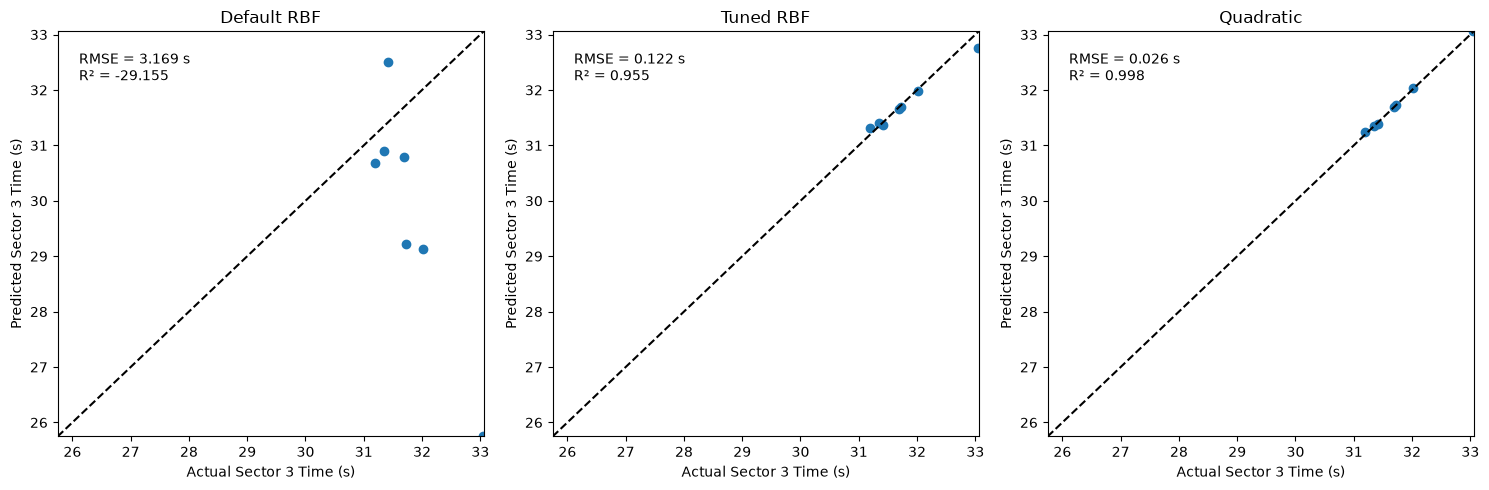

In [144]:
# Step 19 

import matplotlib.pyplot as plt

# Common axis limits
all_values = np.concatenate([
    y_test,
    y_test_pred_default,
    y_test_pred_tuned,
    y_test_pred_quad
])

axis_min = np.min(all_values)
axis_max = np.max(all_values)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# --------------------------------------------------
# Default RBF
# --------------------------------------------------
axes[0].scatter(y_test, y_test_pred_default)

axes[0].plot(
    [axis_min, axis_max],
    [axis_min, axis_max],
    "k--"
)

axes[0].set_xlim(axis_min, axis_max)
axes[0].set_ylim(axis_min, axis_max)

axes[0].set_title("Default RBF")

axes[0].set_xlabel("Actual Sector 3 Time (s)")
axes[0].set_ylabel("Predicted Sector 3 Time (s)")

axes[0].text(
    0.05,
    0.95,
    f"RMSE = {test_rmse_default:.3f} s\nR² = {test_r2_default:.3f}",
    transform=axes[0].transAxes,
    verticalalignment="top"
)

# --------------------------------------------------
# Tuned RBF
# --------------------------------------------------
axes[1].scatter(y_test, y_test_pred_tuned)

axes[1].plot(
    [axis_min, axis_max],
    [axis_min, axis_max],
    "k--"
)

axes[1].set_xlim(axis_min, axis_max)
axes[1].set_ylim(axis_min, axis_max)

axes[1].set_title("Tuned RBF")

axes[1].set_xlabel("Actual Sector 3 Time (s)")
axes[1].set_ylabel("Predicted Sector 3 Time (s)")

axes[1].text(
    0.05,
    0.95,
    f"RMSE = {test_rmse_tuned:.3f} s\nR² = {test_r2_tuned:.3f}",
    transform=axes[1].transAxes,
    verticalalignment="top"
)

# --------------------------------------------------
# Quadratic
# --------------------------------------------------
axes[2].scatter(y_test, y_test_pred_quad)

axes[2].plot(
    [axis_min, axis_max],
    [axis_min, axis_max],
    "k--"
)

axes[2].set_xlim(axis_min, axis_max)
axes[2].set_ylim(axis_min, axis_max)

axes[2].set_title("Quadratic")

axes[2].set_xlabel("Actual Sector 3 Time (s)")
axes[2].set_ylabel("Predicted Sector 3 Time (s)")

axes[2].text(
    0.05,
    0.95,
    f"RMSE = {test_rmse_quad:.3f} s\nR² = {test_r2_quad:.3f}",
    transform=axes[2].transAxes,
    verticalalignment="top"
)

plt.tight_layout()
plt.show()

## Step 19 Markdown Cell

### Test-Set Actual Versus Predicted Results

Actual-versus-predicted plots were generated using only the held-out test
configurations. A 45-degree reference line was included in each panel to
represent perfect predictions.

The default RBF model showed poor agreement with the test data and produced
large prediction errors. The tuned RBF model substantially improved predictive
accuracy after hyperparameter optimization. The quadratic model produced the
closest agreement with the test observations and achieved the lowest test RMSE
and highest test R² among the three models.

## Interpret the evidence

## Step 20

### Model Comparison and Interpretation

Hyperparameter tuning substantially improved the performance of the RBF model. The default RBF model produced a cross-validation RMSE of 5.5055 s and a test RMSE of 3.1692 s, indicating poor predictive performance. After tuning, the RBF cross-validation RMSE decreased to 0.0794 s and the test RMSE decreased to 0.1219 s. The tuned RBF also achieved a test R² of 0.9554, showing that the hyperparameter search greatly improved the model's ability to generalize to unseen configurations.

Despite this improvement, the quadratic reference model remained highly competitive and ultimately outperformed the tuned RBF. The quadratic model achieved the lowest cross-validation RMSE (0.0265 s), the lowest test RMSE (0.0259 s), the lowest test MAE (0.0190 s), and the highest test R² (0.9980). These results indicate that the simpler quadratic model provided the most accurate predictions for this dataset.

The ranking based on cross-validation error agrees with the ranking based on test-set performance. The quadratic model ranked first, the tuned RBF ranked second, and the default RBF ranked third. This agreement increases confidence that the cross-validation procedure provided a useful estimate of predictive performance.

Although the tuned RBF was selected using the minimum cross-validation error among the RBF candidates, its test error does not necessarily equal the minimum cross-validation error. Cross-validation estimates performance using repeated training subsets, whereas the test set consists of a separate collection of unseen configurations. Differences between the training and test configurations, limited sample size, and random variation can all cause test errors to differ from cross-validation errors. Therefore, the tuned RBF should not automatically be assumed to be the best overall model simply because it achieved the lowest cross-validation error among the RBF candidates.

# Task 5: Response Surfaces and Observation Influence

### Plot the final RBF and two omitted observation models

In [145]:
# Step 21: Build Full Dataset

# Inputs from all configurations
X_all = df_grouped[
    ["rear_wing_angle_deg", "rear_ride_height_mm"]
].to_numpy()

# Response from all configurations
y_all = df_grouped[
    "mean_sector_3_time_s"
].to_numpy()

In [146]:
# Step 21: Normalize Using the SAME Bounds

X_all_n = X_all.copy().astype(float)

X_all_n[:, 0] = (
    (X_all[:, 0] - wing_min)
    / (wing_max - wing_min)
)

X_all_n[:, 1] = (
    (X_all[:, 1] - ride_min)
    / (ride_max - ride_min)
)

In [147]:
# Step 21: Fit Tuned RBF Model on All Configurations

b_all = fit_rbf(
    X_all_n,
    y_all,
    sigma_star,
    lam_star
)

In [148]:
# Step 21: Create 101 x 101 Physical Grid

wing_values = np.linspace(
    wing_min,
    wing_max,
    101
)

ride_values = np.linspace(
    ride_min,
    ride_max,
    101
)

Wing_grid, Ride_grid = np.meshgrid(
    wing_values,
    ride_values
)

In [149]:
# Step 21: Normalize Grid

X_grid = np.column_stack([
    Wing_grid.ravel(),
    Ride_grid.ravel()
])

X_grid_n = X_grid.copy()

X_grid_n[:, 0] = (
    (X_grid[:, 0] - wing_min)
    / (wing_max - wing_min)
)

X_grid_n[:, 1] = (
    (X_grid[:, 1] - ride_min)
    / (ride_max - ride_min)
)

In [150]:
# Step 21: Predict and Reshape

y_grid = predict_rbf(
    X_grid_n,
    X_all_n,
    b_all,
    sigma_star
)

Y_grid = y_grid.reshape(
    Wing_grid.shape
)

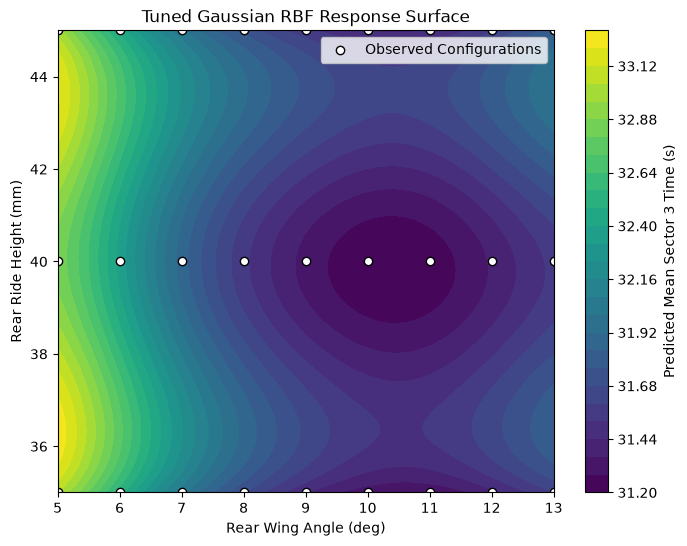

In [151]:
# Step 21: Contour Plot

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

contour = plt.contourf(
    Wing_grid,
    Ride_grid,
    Y_grid,
    levels=30,
    cmap="viridis"
)

plt.colorbar(
    contour,
    label="Predicted Mean Sector 3 Time (s)"
)

# Observed configurations
plt.scatter(
    df_grouped["rear_wing_angle_deg"],
    df_grouped["rear_ride_height_mm"],
    color="white",
    edgecolors="black",
    label="Observed Configurations"
)

plt.xlabel("Rear Wing Angle (deg)")
plt.ylabel("Rear Ride Height (mm)")

plt.title(
    "Tuned Gaussian RBF Response Surface"
)

plt.legend()

plt.show()

## Step 21 Markdown Cell

### Tuned RBF Response Surface

After test-set evaluation was completed, the tuned RBF model was refit using
all configurations in `df_grouped` and the selected hyperparameters

$$
\sigma = 0.652057
$$

and

$$
\lambda = 1.0\times10^{-8}.
$$

Predictions were generated on a 101 × 101 grid spanning the physical design
space. The grid was normalized using the same fixed bounds used throughout the
project. The resulting contour plot shows the predicted mean Sector 3 time
surface together with the observed setup configurations.

In [152]:
# Step 22: Create Training Grid 

# Physical grid
wing_values = np.linspace(
    wing_min,
    wing_max,
    101
)

ride_values = np.linspace(
    ride_min,
    ride_max,
    101
)

Wing_grid, Ride_grid = np.meshgrid(
    wing_values,
    ride_values
)

# Flatten
X_grid = np.column_stack([
    Wing_grid.ravel(),
    Ride_grid.ravel()
])

# Normalize using fixed bounds
X_grid_n = X_grid.copy()

X_grid_n[:, 0] = (
    (X_grid[:, 0] - wing_min)
    / (wing_max - wing_min)
)

X_grid_n[:, 1] = (
    (X_grid[:, 1] - ride_min)
    / (ride_max - ride_min)
)

In [153]:
# Step 22: Create the Three Models

# Training inputs
X_train_full = df_train[
    ["rear_wing_angle_deg", "rear_ride_height_mm"]
].to_numpy()

y_train_full = df_train[
    "mean_sector_3_time_s"
].to_numpy()

# Normalize
X_train_full_n = X_train_full.copy().astype(float)

X_train_full_n[:, 0] = (
    (X_train_full[:, 0] - wing_min)
    / (wing_max - wing_min)
)

X_train_full_n[:, 1] = (
    (X_train_full[:, 1] - ride_min)
    / (ride_max - ride_min)
)

In [154]:
# Step 22: Model 1: All Training Setups 

b_full = fit_rbf(
    X_train_full_n,
    y_train_full,
    sigma_star,
    lam_star
)

Y_full = predict_rbf(
    X_grid_n,
    X_train_full_n,
    b_full,
    sigma_star
).reshape(Wing_grid.shape)

In [155]:
# Step 22: Model 2: Omit Largest Residual Setup

mask_large = (
    df_train["setup_id"] != largest_setup_id
)

df_large_removed = df_train[mask_large]

X_large = df_large_removed[
    ["rear_wing_angle_deg", "rear_ride_height_mm"]
].to_numpy()

y_large = df_large_removed[
    "mean_sector_3_time_s"
].to_numpy()

X_large_n = X_large.copy().astype(float)

X_large_n[:, 0] = (
    (X_large[:, 0] - wing_min)
    / (wing_max - wing_min)
)

X_large_n[:, 1] = (
    (X_large[:, 1] - ride_min)
    / (ride_max - ride_min)
)

b_large = fit_rbf(
    X_large_n,
    y_large,
    sigma_star,
    lam_star
)

Y_large = predict_rbf(
    X_grid_n,
    X_large_n,
    b_large,
    sigma_star
).reshape(Wing_grid.shape)

In [156]:
# Step 22: Model 3: Omit Smallest Residual Setup

mask_small = (
    df_train["setup_id"] != smallest_setup_id
)

df_small_removed = df_train[mask_small]

X_small = df_small_removed[
    ["rear_wing_angle_deg", "rear_ride_height_mm"]
].to_numpy()

y_small = df_small_removed[
    "mean_sector_3_time_s"
].to_numpy()

X_small_n = X_small.copy().astype(float)

X_small_n[:, 0] = (
    (X_small[:, 0] - wing_min)
    / (wing_max - wing_min)
)

X_small_n[:, 1] = (
    (X_small[:, 1] - ride_min)
    / (ride_max - ride_min)
)

b_small = fit_rbf(
    X_small_n,
    y_small,
    sigma_star,
    lam_star
)

Y_small = predict_rbf(
    X_grid_n,
    X_small_n,
    b_small,
    sigma_star
).reshape(Wing_grid.shape)

In [157]:
# Step 22: Common Color Limits

vmin = min(
    Y_full.min(),
    Y_large.min(),
    Y_small.min()
)

vmax = max(
    Y_full.max(),
    Y_large.max(),
    Y_small.max()
)

In [158]:
# Step 22: Largest and Smallest Residual Setup IDs

print("Largest residual setup_id:", largest_setup_id)
print("Smallest residual setup_id:", smallest_setup_id)

Largest residual setup_id: 24.0
Smallest residual setup_id: 17.0


In [159]:
largest_point = df_train[
    df_train["setup_id"] == largest_setup_id
]

smallest_point = df_train[
    df_train["setup_id"] == smallest_setup_id
]

print("Largest residual setup:")
display(largest_point)

print("Smallest residual setup:")
display(smallest_point)

Largest residual setup:


,rear_wing_angle_deg,rear_ride_height_mm,mean_sector_3_time_s,std_sector_3_time_s,valid_laps,setup_id
24,13,35,31.59024,0.0685,5,24


Smallest residual setup:


,rear_wing_angle_deg,rear_ride_height_mm,mean_sector_3_time_s,std_sector_3_time_s,valid_laps,setup_id
17,10,45,31.44488,0.032345,5,17


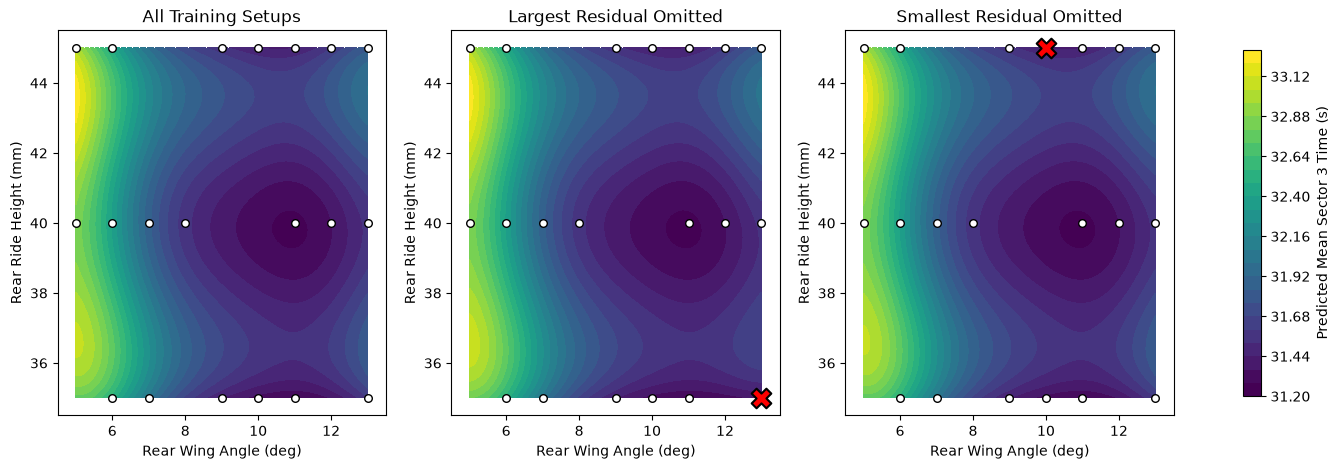

In [160]:
# Step 22: Three Panel Plot

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

surfaces = [
    Y_full,
    Y_large,
    Y_small
]

titles = [
    "All Training Setups",
    "Largest Residual Omitted",
    "Smallest Residual Omitted"
]

for ax, surface, title in zip(
    axes,
    surfaces,
    titles
):

    contour = ax.contourf(
        Wing_grid,
        Ride_grid,
        surface,
        levels=30,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax
    )

    ax.scatter(
        df_train["rear_wing_angle_deg"],
        df_train["rear_ride_height_mm"],
        color="white",
        edgecolors="black",
        s=30
    )

    ax.set_title(title)

    ax.set_xlabel(
        "Rear Wing Angle (deg)"
    )

    ax.set_ylabel(
        "Rear Ride Height (mm)"
    )

for ax in axes:
    ax.set_xlim(4.5, 13.5)
    ax.set_ylim(34.5, 45.5)

# --------------------------
# Mark Ommitted Points
# --------------------------
largest_point = df_train[
    df_train["setup_id"] == largest_setup_id
]

smallest_point = df_train[
    df_train["setup_id"] == smallest_setup_id
]

axes[1].scatter(
    largest_point["rear_wing_angle_deg"],
    largest_point["rear_ride_height_mm"],
    color="red",
    s=200,
    marker="X",
    edgecolors="black",
    linewidths=1.5,
    zorder=10
)

axes[2].scatter(
    smallest_point["rear_wing_angle_deg"],
    smallest_point["rear_ride_height_mm"],
    color="red",
    s=200,
    marker="X",
    edgecolors="black",
    linewidths=1.5,
    zorder=10
)

# --------------------------
# Colorbar and Layout Lines
# --------------------------

# Create a dedicated colorbar axis
cbar = fig.colorbar(
    contour,
    ax=axes,
    location="right",
    shrink=0.9
)

cbar.set_label(
    "Predicted Mean Sector 3 Time (s)"
)

plt.show()

### Explain the model behavior and recommendation

## Step 23 Markdown Cell

### Effect of Hyperparameters and Observation Influence

The Gaussian RBF hyperparameters σ and λ control different aspects of the fitted model. The width parameter σ determines how far the influence of each observation extends through the design space. Small σ values produce highly localized basis functions that can create a complex surface and potentially overfit the training data. Larger σ values produce smoother surfaces because each observation influences a larger region. The regularization parameter λ controls the magnitude of the fitted weights. Increasing λ reduces sensitivity to individual observations and can improve numerical stability, while very small λ values allow the model to fit the data more closely.

Training RMSE is not an appropriate criterion for selecting σ and λ because a model can achieve very low training error while performing poorly on unseen configurations. This behavior was demonstrated by the default RBF model, which produced a relatively small training RMSE but a much larger cross-validation error. Leave-one-out cross validation provides a more realistic measure of predictive performance and was therefore used for hyperparameter selection.

The RMSE_CV contour plot showed that the selected hyperparameters were

$$
\sigma = 0.652057
$$

and

$$
\lambda = 1.0\times10^{-8}.
$$

The minimum occurred on the lower λ boundary, indicating that very little regularization was preferred within the tested search range. The low-error region appeared relatively broad, suggesting that performance was not extremely sensitive to small hyperparameter changes near the selected solution.

The three response surfaces showed that omitting observations does affect the fitted model, but the effect is localized rather than global. Removing the setup with the largest absolute LOOCV residual produced a more noticeable change in the neighboring region of the surface than removing the setup with the smallest residual. However, the overall surface structure remained similar across all three plots. This illustrates that a large prediction error for a particular omitted observation does not necessarily imply a large change throughout the entire response surface. The influence of an observation depends on both its location in the design space and the information provided by nearby observations.

## Step 24 Markdown Cell

### Final Model Recommendation

Based on both the cross-validation and test-set results, the quadratic model is recommended for predicting mean Sector 3 time. The quadratic model achieved the lowest cross-validation RMSE (0.0265 s), the lowest test RMSE (0.0259 s), the lowest test MAE (0.0190 s), and the highest test R² (0.9980). Although hyperparameter tuning greatly improved the RBF model relative to the default settings, the quadratic model consistently outperformed the tuned RBF on both the training-validation and independent test evaluations.

The tuned RBF model remains a useful nonlinear modeling approach and achieved strong predictive performance, with RMSE_CV = 0.0794 s and test R² = 0.9554. However, the additional complexity of the RBF model did not provide a predictive advantage for this dataset. The agreement between the cross-validation ranking and the test-set ranking increases confidence in the conclusion that the quadratic model is the preferred predictor.

Several limitations should be considered when interpreting these results. The dataset contains only 27 setup configurations, resulting in relatively sparse coverage of the design space. The response values represent mean Sector 3 times computed from a limited number of laps, so measurement noise remains present even after averaging. The hyperparameter search was restricted to a finite range of σ and λ values, and the selected λ occurred on the lower search boundary, suggesting that a different search range could potentially identify alternative RBF solutions. Numerical conditioning may also affect RBF solutions when regularization becomes extremely small.

After model selection, the tuned RBF was refit using all available configurations to generate the final response surface. However, this all-data refit no longer has an independent test set available for validation because every observation was used during fitting. Consequently, the resulting surface should be viewed as a predictive model rather than a verified physical optimum. In addition, the response surface only predicts Sector 3 time and does not enforce or verify the top-speed constraint considered in Project 2. Therefore, the response surface alone cannot be used to establish an optimal vehicle setup without considering additional engineering requirements.

# ------------------------------------------

# Task 6: Neural Networks with CSV Lap Time Data

In [161]:
# Step 25

import pandas as pd
from IPython.display import display

# Load lap time dataset
df_laptime = pd.read_csv("simulated_laptime_data.csv")

# Add row_id using original zero-based index
df_laptime["row_id"] = df_laptime.index

print("First five rows:")
display(df_laptime.head())

print("\nSummary statistics:")
display(df_laptime.describe())

print("\nRow count:")
print(len(df_laptime))

print("\nMissing-value counts:")
display(df_laptime.isna().sum())


# Inputs (required order)
X_laptime = df_laptime[
    ["fuel_kg", "tire_age_laps"]
].to_numpy()

# Response (1-D)
y_laptime = df_laptime["time_s"].to_numpy()

print("Input matrix shape:", X_laptime.shape)
print("Response shape:", y_laptime.shape)

First five rows:


,fuel_kg,tire_age_laps,time_s,row_id
0,22.189146,7.846392,64.810266,0
1,29.207419,5.174721,65.917722,1
2,16.306554,10.407846,65.457985,2
3,29.178391,7.585621,65.778464,3
4,18.989303,9.723292,65.446376,4



Summary statistics:


,fuel_kg,tire_age_laps,time_s,row_id
count,100.000000,100.000000,100.000000,100.000000
mean,22.209104,6.037854,65.101500,49.500000
std,4.615793,3.263998,0.964395,29.011492
min,14.093194,0.200674,63.108675,0.000000
25%,18.199190,3.511454,64.372019,24.750000
50%,22.223122,5.598018,65.020940,49.500000
75%,26.468585,9.008879,65.619956,74.250000
max,29.691795,11.988311,67.987389,99.000000



Row count:
100

Missing-value counts:


fuel_kg          0
tire_age_laps    0
time_s           0
row_id           0
dtype: int64

Input matrix shape: (100, 2)
Response shape: (100,)


## Step 25 Markdown Cell

### Lap Time Dataset Exploration

The file `simulated_laptime_data.csv` was loaded using `pd.read_csv`. A unique
`row_id` was added using the original zero-based row index to preserve the
identity of each observation.

The input variables are:

- fuel_kg
- tire_age_laps

The response variable is:

- time_s

Unlike the IMS setup dataset used in Tasks I–V, these observations were not
aggregated into setup means. Each row was retained as an individual observation
for neural-network modeling and evaluation.

In [162]:
# Step 26: Train/Test Split

from sklearn.model_selection import train_test_split

# Train-test split
df_train_lap, df_test_lap = train_test_split(
    df_laptime,
    test_size=0.25,
    random_state=42
)

print("Training observations:", len(df_train_lap))
print("Test observations:", len(df_test_lap))


Training observations: 75
Test observations: 25


In [163]:
# Step 26: Create Inputs and Responses

# Inputs
X_train_lap = df_train_lap[
    ["fuel_kg", "tire_age_laps"]
].to_numpy()

X_test_lap = df_test_lap[
    ["fuel_kg", "tire_age_laps"]
].to_numpy()

# Response
y_train_lap = df_train_lap["time_s"].to_numpy()
y_test_lap = df_test_lap["time_s"].to_numpy()

In [164]:
# Step 26: Compute Bounds Using ONLY Training Data

fuel_min = X_train_lap[:, 0].min()
fuel_max = X_train_lap[:, 0].max()

tire_min = X_train_lap[:, 1].min()
tire_max = X_train_lap[:, 1].max()

print("Fuel load bounds:")
print(fuel_min, "to", fuel_max)

print("\nTire age bounds:")
print(tire_min, "to", tire_max)

Fuel load bounds:
14.093193521727695 to 29.691795196819818

Tire age bounds:
0.20192741616255594 to 11.98831058788725


In [165]:
# Step 26: Normalize Training and Test Inputs

X_train_lap_n = X_train_lap.copy().astype(float)
X_test_lap_n = X_test_lap.copy().astype(float)

# Fuel load
X_train_lap_n[:, 0] = (
    (X_train_lap[:, 0] - fuel_min)
    / (fuel_max - fuel_min)
)

X_test_lap_n[:, 0] = (
    (X_test_lap[:, 0] - fuel_min)
    / (fuel_max - fuel_min)
)

# Tire age
X_train_lap_n[:, 1] = (
    (X_train_lap[:, 1] - tire_min)
    / (tire_max - tire_min)
)

X_test_lap_n[:, 1] = (
    (X_test_lap[:, 1] - tire_min)
    / (tire_max - tire_min)
)

print("Normalized training shape:", X_train_lap_n.shape)
print("Normalized test shape:", X_test_lap_n.shape)

Normalized training shape: (75, 2)
Normalized test shape: (25, 2)


## Step 26 Markdown Cell

### Training-Test Split and Input Normalization

The dataset was divided into training and test sets using

$$
\text{test\_size}=0.25
$$

and

$$
\text{random\_state}=42.
$$

This produced 75 training observations and 25 test observations.

Normalization bounds were computed using only the training observations.

Fuel load bounds:

- Minimum: 14.093193521727695
- Maximum: 29.691795196819818

Tire age bounds:

- Minimum: 0.20192741616255594
- Maximum: 11.98831058788725

The same bounds were used to normalize the training inputs, test inputs, and future plotting grids. The response variable \(time_s\) was not normalized. Test and grid values were not clipped, even if they fell outside the interval \([0,1]\).

## Train and evaluate fixed models

In [166]:
# Step 27: Imports

from sklearn.neural_network import MLPRegressor
import warnings

In [167]:
# Step 27: ReLU Network

# ReLU network
mlp_relu = MLPRegressor(
    hidden_layer_sizes=(20, 20),
    activation="relu",
    solver="lbfgs",
    alpha=0.1,
    max_iter=5000,
    random_state=1
)

mlp_relu.fit(
    X_train_lap_n,
    y_train_lap
)

print("ReLU n_iter_:", mlp_relu.n_iter_)

ReLU n_iter_: 360


In [168]:
# Step 27: Tanh Network

# Tanh network
mlp_tanh = MLPRegressor(
    hidden_layer_sizes=(20, 20),
    activation="tanh",
    solver="lbfgs",
    alpha=0.1,
    max_iter=5000,
    random_state=1
)

mlp_tanh.fit(
    X_train_lap_n,
    y_train_lap
)

print("Tanh n_iter_:", mlp_tanh.n_iter_)

Tanh n_iter_: 1705


In [169]:
# Step 27: Training Predictions

# Training predictions
y_train_relu = mlp_relu.predict(
    X_train_lap_n
)

y_train_tanh = mlp_tanh.predict(
    X_train_lap_n
)

# Test predictions
y_test_relu = mlp_relu.predict(
    X_test_lap_n
)

y_test_tanh = mlp_tanh.predict(
    X_test_lap_n
)

## Step 27 Markdown Cell

### Neural Network Training

Two MLPRegressor models were trained using the normalized lap-time training
observations. Both models used:

$$
(20,20)
$$

hidden neurons,

$$
\alpha = 0.1
$$

L2 regularization,

the L-BFGS solver,

and

$$
\text{random\_state}=1.
$$

The only difference between the models was the activation function. One model
used ReLU activation and the other used tanh activation.

The architecture, regularization strength, solver, and random seed were kept
fixed to allow a direct comparison of the activation functions.

The ReLU network converged after 360 iterations, while the tanh network
converged after 1705 iterations. No convergence warnings were observed for
either model.

In [170]:
# Step 28: Fit Quadratic Reference Model

# Training design matrix
A_train_lap = create_quadratic_design_matrix(
    X_train_lap_n
)

# Test design matrix
A_test_lap = create_quadratic_design_matrix(
    X_test_lap_n
)

# Fit quadratic model
b_quad_lap = np.linalg.pinv(
    A_train_lap
) @ y_train_lap

# Predictions
y_train_quad_lap = A_train_lap @ b_quad_lap
y_test_quad_lap = A_test_lap @ b_quad_lap

In [171]:
# Step 28: Calculate Metrics

# ReLU metrics
train_rmse_relu = rmse(
    y_train_lap,
    y_train_relu
)

test_rmse_relu = rmse(
    y_test_lap,
    y_test_relu
)

test_mae_relu = mae(
    y_test_lap,
    y_test_relu
)

test_r2_relu = r2_score_manual(
    y_test_lap,
    y_test_relu
)

# Tanh metrics
train_rmse_tanh = rmse(
    y_train_lap,
    y_train_tanh
)

test_rmse_tanh = rmse(
    y_test_lap,
    y_test_tanh
)

test_mae_tanh = mae(
    y_test_lap,
    y_test_tanh
)

test_r2_tanh = r2_score_manual(
    y_test_lap,
    y_test_tanh
)

# Quadratic metrics
train_rmse_quad_lap = rmse(
    y_train_lap,
    y_train_quad_lap
)

test_rmse_quad_lap = rmse(
    y_test_lap,
    y_test_quad_lap
)

test_mae_quad_lap = mae(
    y_test_lap,
    y_test_quad_lap
)

test_r2_quad_lap = r2_score_manual(
    y_test_lap,
    y_test_quad_lap
)


In [172]:
# Step 28: Build Required Table

df_laptime_metrics = pd.DataFrame({
    "model": [
        "MLP",
        "MLP",
        "Quadratic"
    ],

    "activation": [
        "relu",
        "tanh",
        ""
    ],

    "train_RMSE_s": [
        train_rmse_relu,
        train_rmse_tanh,
        train_rmse_quad_lap
    ],

    "test_RMSE_s": [
        test_rmse_relu,
        test_rmse_tanh,
        test_rmse_quad_lap
    ],

    "test_MAE_s": [
        test_mae_relu,
        test_mae_tanh,
        test_mae_quad_lap
    ],

    "test_R2": [
        test_r2_relu,
        test_r2_tanh,
        test_r2_quad_lap
    ],

    "n_iter": [
        mlp_relu.n_iter_,
        mlp_tanh.n_iter_,
        ""
    ]
})

display(df_laptime_metrics)

,model,activation,train_RMSE_s,test_RMSE_s,test_MAE_s,test_R2,n_iter
0,MLP,relu,0.430842,0.550548,0.414171,0.693431,360
1,MLP,tanh,0.310246,0.405922,0.263007,0.833344,1705
2,Quadratic,,0.535688,0.590557,0.431262,0.647255,


In [173]:
# Step 28: Save Required CSV

df_laptime_metrics.to_csv(
    "cvanvoor_pr03_laptime_metrics.csv",
    index=False
)

print(
    "cvanvoor_pr03_laptime_metrics.csv saved."
)

cvanvoor_pr03_laptime_metrics.csv saved.


## Step 28 Markdown Cell

### Lap-Time Model Comparison

The ReLU MLP, tanh MLP, and quadratic reference model were evaluated using the
same training and test observations.

The neural networks used the required fixed architecture, solver,
regularization parameter, and random seed. No additional tuning was performed
after observing the test-set results.

Among the three models, the tanh neural network achieved the lowest test RMSE,
lowest test MAE, and highest test R², indicating the strongest predictive
performance on the held-out observations. The ReLU neural network also
outperformed the quadratic reference model, while the quadratic model produced
the largest test error of the three models.

The resulting metrics were saved to
`cvanvoor_pr03_laptime_metrics.csv`.

In [174]:
# Step 29: Create Predictions for All 100 Observations

# Inputs for all observations
X_all_lap = df_laptime[
    ["fuel_kg", "tire_age_laps"]
].to_numpy()

# Normalize using TRAINING bounds only
X_all_lap_n = X_all_lap.copy().astype(float)

X_all_lap_n[:, 0] = (
    (X_all_lap[:, 0] - fuel_min)
    / (fuel_max - fuel_min)
)

X_all_lap_n[:, 1] = (
    (X_all_lap[:, 1] - tire_min)
    / (tire_max - tire_min)
)


In [175]:
# Step 29: Generate Predictions

# Neural-network predictions
relu_all_pred = mlp_relu.predict(X_all_lap_n)

tanh_all_pred = mlp_tanh.predict(X_all_lap_n)

# Quadratic predictions
A_all_lap = create_quadratic_design_matrix(
    X_all_lap_n
)

quad_all_pred = A_all_lap @ b_quad_lap

In [176]:
# Step 29: Create Split Column

# Create split indicator
df_predictions = df_laptime.copy()

df_predictions["split"] = "test"

df_predictions.loc[
    df_train_lap.index,
    "split"
] = "train"

In [177]:
# Step 29: Build Required CSV

# Start fresh from original dataframe
df_predictions = df_laptime.copy()

# Create split column
df_predictions["split"] = "test"

df_predictions.loc[
    df_train_lap.index,
    "split"
] = "train"

# Rename response column
df_predictions = df_predictions.rename(
    columns={
        "time_s": "actual_time_s"
    }
)

# Add predictions
df_predictions["relu_prediction_s"] = relu_all_pred
df_predictions["tanh_prediction_s"] = tanh_all_pred
df_predictions["quadratic_prediction_s"] = quad_all_pred

# Final required column order
df_predictions = df_predictions[
    [
        "row_id",
        "split",
        "fuel_kg",
        "tire_age_laps",
        "actual_time_s",
        "relu_prediction_s",
        "tanh_prediction_s",
        "quadratic_prediction_s"
    ]
]

display(df_predictions.head())

print(df_predictions.shape)

,row_id,split,fuel_kg,tire_age_laps,actual_time_s,relu_prediction_s,tanh_prediction_s,quadratic_prediction_s
0,0,test,22.189146,7.846392,64.810266,64.587493,64.684298,64.709888
1,1,train,29.207419,5.174721,65.917722,66.327038,65.949959,66.117398
2,2,train,16.306554,10.407846,65.457985,64.928056,65.306798,64.981211
3,3,train,29.178391,7.585621,65.778464,65.722361,65.727084,66.025416
4,4,test,18.989303,9.723292,65.446376,64.584118,65.102085,64.534772


(100, 8)


In [178]:
# Step 29: Save Required CSV

df_predictions.to_csv(
    "cvanvoor_pr03_laptime_predictions.csv",
    index=False
)

print(
    "cvanvoor_pr03_laptime_predictions.csv saved."
)

cvanvoor_pr03_laptime_predictions.csv saved.


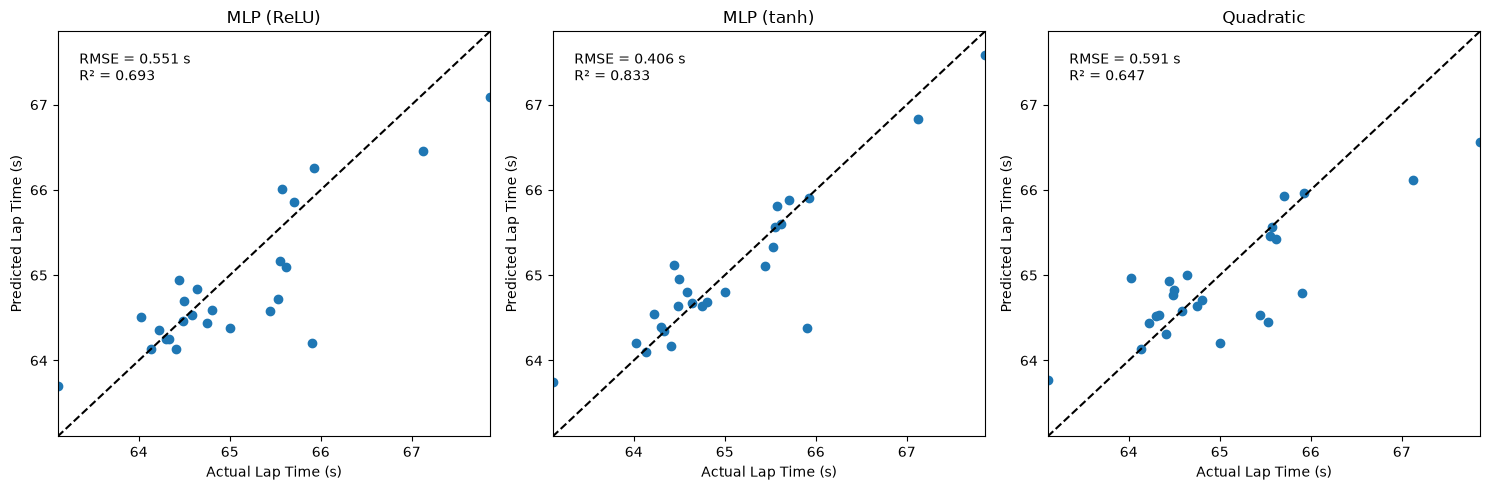

In [179]:
# Step 29: Validation Figure

import matplotlib.pyplot as plt

all_values = np.concatenate([
    y_test_lap,
    y_test_relu,
    y_test_tanh,
    y_test_quad_lap
])

axis_min = np.min(all_values)
axis_max = np.max(all_values)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)

# -----------------------------
# ReLU
# -----------------------------
axes[0].scatter(
    y_test_lap,
    y_test_relu
)

axes[0].plot(
    [axis_min, axis_max],
    [axis_min, axis_max],
    "k--"
)

axes[0].set_xlim(axis_min, axis_max)
axes[0].set_ylim(axis_min, axis_max)

axes[0].set_title("MLP (ReLU)")

axes[0].set_xlabel("Actual Lap Time (s)")
axes[0].set_ylabel("Predicted Lap Time (s)")

axes[0].text(
    0.05,
    0.95,
    f"RMSE = {test_rmse_relu:.3f} s\nR² = {test_r2_relu:.3f}",
    transform=axes[0].transAxes,
    verticalalignment="top"
)

# -----------------------------
# Tanh
# -----------------------------
axes[1].scatter(
    y_test_lap,
    y_test_tanh
)

axes[1].plot(
    [axis_min, axis_max],
    [axis_min, axis_max],
    "k--"
)

axes[1].set_xlim(axis_min, axis_max)
axes[1].set_ylim(axis_min, axis_max)

axes[1].set_title("MLP (tanh)")

axes[1].set_xlabel("Actual Lap Time (s)")
axes[1].set_ylabel("Predicted Lap Time (s)")

axes[1].text(
    0.05,
    0.95,
    f"RMSE = {test_rmse_tanh:.3f} s\nR² = {test_r2_tanh:.3f}",
    transform=axes[1].transAxes,
    verticalalignment="top"
)

# -----------------------------
# Quadratic
# -----------------------------
axes[2].scatter(
    y_test_lap,
    y_test_quad_lap
)

axes[2].plot(
    [axis_min, axis_max],
    [axis_min, axis_max],
    "k--"
)

axes[2].set_xlim(axis_min, axis_max)
axes[2].set_ylim(axis_min, axis_max)

axes[2].set_title("Quadratic")

axes[2].set_xlabel("Actual Lap Time (s)")
axes[2].set_ylabel("Predicted Lap Time (s)")

axes[2].text(
    0.05,
    0.95,
    f"RMSE = {test_rmse_quad_lap:.3f} s\nR² = {test_r2_quad_lap:.3f}",
    transform=axes[2].transAxes,
    verticalalignment="top"
)

plt.tight_layout()

plt.savefig(
    "cvanvoor_pr03_laptime_validation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Plot the contours and interpret the results

In [180]:
# Step 30: Create Physical Grid

# Physical ranges from full CSV
fuel_values = np.linspace(
    df_laptime["fuel_kg"].min(),
    df_laptime["fuel_kg"].max(),
    50
)

tire_values = np.linspace(
    df_laptime["tire_age_laps"].min(),
    df_laptime["tire_age_laps"].max(),
    50
)

Fuel_grid, Tire_grid = np.meshgrid(
    fuel_values,
    tire_values
)


In [181]:
# Step 30: Form X_grid

X_grid = np.column_stack([
    Fuel_grid.ravel(),
    Tire_grid.ravel()
])

In [182]:
# Step 30: Normalize X_grid Using Training Bounds

X_grid_n = X_grid.copy().astype(float)

# Fuel
X_grid_n[:, 0] = (
    (X_grid[:, 0] - fuel_min)
    / (fuel_max - fuel_min)
)

# Tire age
X_grid_n[:, 1] = (
    (X_grid[:, 1] - tire_min)
    / (tire_max - tire_min)
)

In [183]:
# Step 30: Generate Predictions for Each Model

# ReLU predictions
relu_grid = mlp_relu.predict(
    X_grid_n
).reshape(Fuel_grid.shape)


# Tanh predictions
tanh_grid = mlp_tanh.predict(
    X_grid_n
).reshape(Fuel_grid.shape)


# Quadratic predictions
A_grid = create_quadratic_design_matrix(
    X_grid_n
)

quad_grid = (
    A_grid @ b_quad_lap
).reshape(Fuel_grid.shape)

In [184]:
# Step 30: Common Color Limits

vmin = min(
    relu_grid.min(),
    tanh_grid.min(),
    quad_grid.min()
)

vmax = max(
    relu_grid.max(),
    tanh_grid.max(),
    quad_grid.max()
)

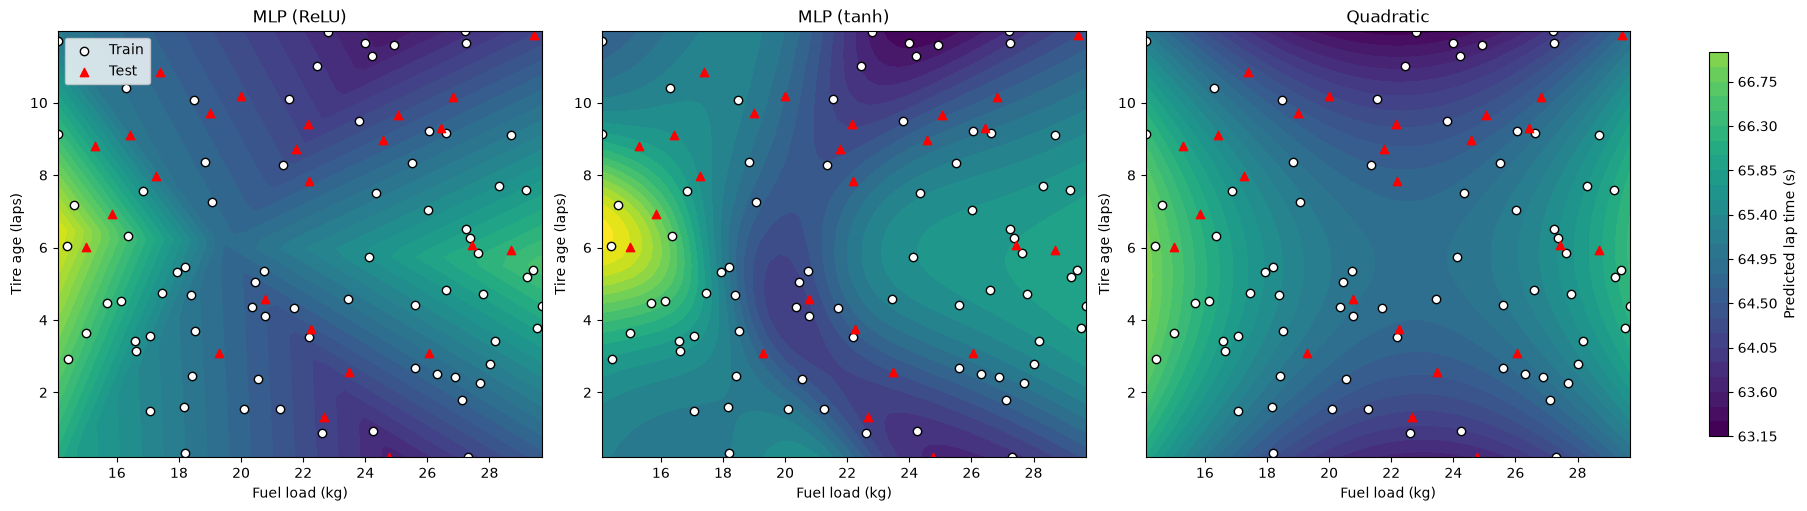

In [185]:
# Step 30: Create Figure

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5),
    constrained_layout=True
)

surfaces = [
    relu_grid,
    tanh_grid,
    quad_grid
]

titles = [
    "MLP (ReLU)",
    "MLP (tanh)",
    "Quadratic"
]

for ax, surface, title in zip(
    axes,
    surfaces,
    titles
):

    contour = ax.contourf(
        Fuel_grid,
        Tire_grid,
        surface,
        levels=30,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax
    )

    # Training observations
    ax.scatter(
        df_train_lap["fuel_kg"],
        df_train_lap["tire_age_laps"],
        marker="o",
        color="white",
        edgecolors="black",
        label="Train"
    )

    # Test observations
    ax.scatter(
        df_test_lap["fuel_kg"],
        df_test_lap["tire_age_laps"],
        marker="^",
        color="red",
        label="Test"
    )

    ax.set_title(title)

    ax.set_xlabel(
        "Fuel load (kg)"
    )

    ax.set_ylabel(
        "Tire age (laps)"
    )

# Shared colorbar
cbar = fig.colorbar(
    contour,
    ax=axes,
    location="right",
    shrink=0.9
)

cbar.set_label(
    "Predicted lap time (s)"
)

axes[0].legend()

plt.savefig(
    "cvanvoor_pr03_laptime_surfaces.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## Step 30 Markdown Cell

### Lap-Time Response Surfaces

A 50 × 50 meshgrid was created spanning the observed fuel-load and tire-age
ranges in the supplied CSV file. The grid was normalized using the minimum and
maximum values computed from the training observations. The ReLU neural
network, tanh neural network, and quadratic reference model were then used to
predict lap time over the grid.

Contour plots were generated using common color limits to allow direct
comparison between the three models. Training and test observations were
displayed using different markers to illustrate data coverage across the
design space.

The resulting figure was saved as
`cvanvoor_pr03_laptime_surfaces.png`.

# Step 31

### Neural Network Comparison and Interpretation

The ReLU and tanh neural networks use different activation functions to introduce nonlinearity into the model. The ReLU activation outputs zero for negative inputs and a linear response for positive inputs, which can produce piecewise-linear response surfaces. The tanh activation is a smooth sigmoidal function with outputs between -1 and 1, often leading to smoother transitions in predicted responses.

The contour plots indicate that the tanh and ReLU models produce somewhat different response surfaces across the fuel-load and tire-age design space. The tanh surface generally appears smoother, while the ReLU surface may contain sharper changes in slope due to its piecewise-linear behavior. However, visual smoothness alone does not guarantee better predictive performance.

Among the evaluated models, the tanh neural network achieved the lowest test RMSE (0.4059 s), the lowest test MAE (0.2630 s), and the highest test R² (0.8333). The ReLU network ranked second, while the quadratic model produced the largest test errors. In this case, the smoother tanh surface also produced the best predictive performance, although this relationship should not be assumed to hold for other datasets.

The learned parameters of the neural networks are the weights and biases estimated during training. In contrast, the network architecture, activation function, alpha value, solver, maximum iterations, and random seed are fixed hyperparameters chosen before training.

These results are based on a single train-test split. Different splits could produce different rankings or error values. In addition, predictions in sparsely sampled regions of the fuel-load and tire-age space are generally less reliable because fewer nearby observations are available to constrain the fitted models.